### PART1: Dataset overview & inspection
#### SOURCE OF DATA: Abd, Mahdi & Jahani (2025), Rheumatic and Autoimmune Diseases Dataset, Harvard Dataverse, https://doi.org/10.7910/DVN/VM4OR3 (CC BY 4.0).
#### Original source file (clean, unmodified, read-only) = 12,085 records, 15 columns
#### Modified the source file for duplicate rows, outliers, date time field(test date) and categorical value inconsistencies using claude)

#### DOMAIN: Clinical rheumatology/immunology — lab serology data for diagnosing rheumatic and autoimmune diseases.

#### PURPOSE: To detect Rheumatic and Autoimmune disease in the early stages with the help of lab biomarkers.

### I imported the required libraries for the purpose od exploratory data analysis of this data set.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# not limiting number of columns and rows shown
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)

# making the columns wider using 140 as maximum number of characters per line that pandas
# can fit before wrapping to next line
pd.set_option("display.width", 140)

### I loaded the data set using pd.read_excel as the file is'xlsx'

In [2]:
# loading dataset
# file is '.xlsx' file
df = pd.read_excel("Rheumatic and Autoimmune Disease Dataset_modified.xlsx")

### Printed the first 20 rows of data set using .head()

In [3]:
# first 20 rows
df.head(20)

,Age,Gender,Test_Date,ESR,CRP,RF,Anti-CCP,HLA-B27,ANA,Anti-Ro,Anti-La,Anti-dsDNA,Anti-Sm,C3,C4,Disease
0,70,Male,25-Feb-2019,39.0,18.6,34.2,29.9,Positive,Negative,Positive,Negative,Positive,Positive,NaN,27.0,Rheumatoid Arthritis
1,39,Female,43580,26.0,21.7,35.5,28.9,Negative,NaN,Positive,NaN,Positive,NaN,100.0,66.0,Rheumatoid Arthritis
2,36,Female,05-29-2020,41.0,15.6,21.3,21.3,Negative,Negative,NaN,Positive,Negative,NaN,158.0,12.0,Rheumatoid Arthritis
3,35,Male,2025-02-10,43.0,23.4,26.0,39.0,NaN,NaN,Positive,Positive,NaN,NaN,119.0,41.0,Rheumatoid Arthritis
4,37,Female,15/06/2020,30.0,NaN,38.1,30.8,Positive,Negative,Positive,Negative,Positive,Negative,144.0,49.0,Rheumatoid Arthritis
5,41,Female,2023-11-09,36.0,12.5,NaN,37.3,Positive,NaN,Negative,Negative,NaN,Negative,169.0,71.0,Rheumatoid Arthritis
6,32,Male,2021-12-06,42.0,27.5,22.3,NaN,Negative,Positive,Negative,NaN,Positive,Positive,146.0,21.0,Rheumatoid Arthritis
7,60,Female,04-13-2019,39.0,19.3,31.8,38.1,Negative,Positive,Negative,Negative,Positive,Positive,100.0,NaN,Rheumatoid Arthritis
8,51,Female,09-Feb-2022,29.0,18.1,33.4,NaN,NaN,NaN,Positive,NaN,Positive,NaN,166.0,65.0,Rheumatoid Arthritis
9,68,Female,2019-03-14,37.0,NaN,37.4,25.0,Positive,Negative,Negative,NaN,Positive,Positive,123.0,50.0,Rheumatoid Arthritis


### Showed the column names and datatypes of column names by using .info()
### There are 16 columns with data types float, integer, object and string¶

In [4]:
# column names and data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12140 entries, 0 to 12139
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Age         12140 non-null  int64  
 1   Gender      12140 non-null  str    
 2   Test_Date   11757 non-null  object 
 3   ESR         11049 non-null  float64
 4   CRP         9713 non-null   float64
 5   RF          10806 non-null  float64
 6   Anti-CCP    8863 non-null   float64
 7   HLA-B27     10198 non-null  str    
 8   ANA         8382 non-null   str    
 9   Anti-Ro     9223 non-null   str    
 10  Anti-La     9105 non-null   str    
 11  Anti-dsDNA  7407 non-null   str    
 12  Anti-Sm     6917 non-null   str    
 13  C3          10439 non-null  float64
 14  C4          10077 non-null  float64
 15  Disease     12140 non-null  str    
dtypes: float64(6), int64(1), object(1), str(8)
memory usage: 2.2+ MB


###  Displayed the  number of rows and columns in dataset using .shape.
#### The number of rows are 12140 and number of columns is 16

In [5]:
# printing the number of rows and columns
rows, columns = df.shape
print(f"Number of rows:{rows}")
print(f"Number of columns:{columns}")

Number of rows:12140
Number of columns:16


### Except for the categorical columns that is age,gender,disease rest of the columns have missing values. The missing values displayed as bool.

In [6]:
# finding missing values
df.isnull().any()

Age           False
Gender        False
Test_Date      True
ESR            True
CRP            True
RF             True
Anti-CCP       True
HLA-B27        True
ANA            True
Anti-Ro        True
Anti-La        True
Anti-dsDNA     True
Anti-Sm        True
C3             True
C4             True
Disease       False
dtype: bool

### Checked for mixed data types Test_Date has 3 datatypes : string , float, integer.
### HLA-B27, ANA, Anti-Ro, Anti-La, Anti-dsDNA, Anti-Sm have 2 data types : string and float.
### since floats can also represent null values we have to check if they are real float values or null values.

In [7]:
# checking for mixed data types
for col in df.columns:  # iterating through the columns
    print(f"--Column:{col}---")  # generates organized output
    print(df[col].apply(type).value_counts())  # applies data type to each row
    print()  # blank line for readadbility

--Column:Age---
Age
<class 'int'>    12140
Name: count, dtype: int64

--Column:Gender---
Gender
<class 'str'>    12140
Name: count, dtype: int64

--Column:Test_Date---
Test_Date
<class 'str'>      11390
<class 'float'>      383
<class 'int'>        367
Name: count, dtype: int64

--Column:ESR---
ESR
<class 'float'>    12140
Name: count, dtype: int64

--Column:CRP---
CRP
<class 'float'>    12140
Name: count, dtype: int64

--Column:RF---
RF
<class 'float'>    12140
Name: count, dtype: int64

--Column:Anti-CCP---
Anti-CCP
<class 'float'>    12140
Name: count, dtype: int64

--Column:HLA-B27---
HLA-B27
<class 'str'>      10198
<class 'float'>     1942
Name: count, dtype: int64

--Column:ANA---
ANA
<class 'str'>      8382
<class 'float'>    3758
Name: count, dtype: int64

--Column:Anti-Ro---
Anti-Ro
<class 'str'>      9223
<class 'float'>    2917
Name: count, dtype: int64

--Column:Anti-La---
Anti-La
<class 'str'>      9105
<class 'float'>    3035
Name: count, dtype: int64

--Column:Anti-dsDN

## column test dates has three different data types(float,string,integer).here all floats are null counts so it has two mixed datatypes.
### columns HLA-B27,ANA,Anti-Ro,Anti-La,Anti-dsDNA,Anti=Sm,C3,C4 have str and floats but floats represents empty values in these lab values.so there are no mixed data types.

In [8]:
# checking the floats in the columns
# creating a python list
lab_columns = [
    "Test_Date",
    "HLA-B27",
    "ANA",
    "Anti-Ro",
    "Anti-La",
    "Anti-dsDNA",
    "Anti-Sm",
    "C3",
    "C4",
]
# creatin an empty dictionary to hold the final values for each key value pair
lab_values = {}

for col in lab_columns:
    if col in df.columns:  # proceeses column present in dataset
        # counts the rows with floats
        count_float = (
            df[col].apply(type) == float
        ).sum()  # checking datatype of every value of column
        float_null = (
            df[df[col].apply(type) == float][col].isna().sum()
        )  # keeps only the rows where elements are floats
        lab_values[col] = {
            "Float Count": count_float,
            "Null Floats": float_null,
        }  # saves values in the empty dictionary

print(lab_values)

{'Test_Date': {'Float Count': np.int64(383), 'Null Floats': np.int64(383)}, 'HLA-B27': {'Float Count': np.int64(1942), 'Null Floats': np.int64(1942)}, 'ANA': {'Float Count': np.int64(3758), 'Null Floats': np.int64(3758)}, 'Anti-Ro': {'Float Count': np.int64(2917), 'Null Floats': np.int64(2917)}, 'Anti-La': {'Float Count': np.int64(3035), 'Null Floats': np.int64(3035)}, 'Anti-dsDNA': {'Float Count': np.int64(4733), 'Null Floats': np.int64(4733)}, 'Anti-Sm': {'Float Count': np.int64(5223), 'Null Floats': np.int64(5223)}, 'C3': {'Float Count': np.int64(12140), 'Null Floats': np.int64(1701)}, 'C4': {'Float Count': np.int64(12140), 'Null Floats': np.int64(2063)}}


### checked if there are any numeric data in text heavy columns. No inconsistencies observed.

In [9]:
# identifying inconsistencies in format
# selecting all the object datatypes
text_cols = df.select_dtypes(
    include=["string"]
)  # include string looks for columns using string extensions
print(text_cols.sample(10))

      Gender   HLA-B27       ANA   Anti-Ro   Anti-La Anti-dsDNA   Anti-Sm                 Disease
2004  Female  Positive  Negative  Positive  Positive   Negative  Negative    Rheumatoid Arthritis
443   Female  Negative  Negative       NaN  Negative   Positive       NaN    Rheumatoid Arthritis
5524    Male  Positive  Positive  Positive  Positive        NaN       NaN      Sjögren's Syndrome
6855  Female  Positive       NaN  Positive  Positive   Negative  Negative      Sjögren's Syndrome
924   Female  Positive  Positive       NaN  Negative        NaN  Positive    Rheumatoid Arthritis
5531    Male  Positive       NaN  Positive       NaN        NaN       NaN      Sjögren's Syndrome
3973    Male  Positive  Positive       NaN  Positive        NaN  Negative  Ankylosing Spondylitis
4285    Male  Positive       NaN  Positive  Negative   Negative  Positive  Ankylosing Spondylitis
5739    Male  Positive  Positive       NaN  Positive        pos       NaN      Sjögren's Syndrome
5041    Male  Positi


### Inconsistencies in case format
#### There are inconsistencies in case for columns'Gender', 'HLA-B27', 'ANA', 'Anti-La', 'Anti-Ro', 'Anti-Sm', 'Anti-dsDNA'.

In [10]:
# checking for case inconsistencies
text_cols = [
    "Gender",
    "HLA-B27",
    "ANA",
    "Anti-La",
    "Anti-Ro",
    "Anti-dsDNA",
    "Anti-Sm",
    "Disease",
]
for col in text_cols:
    clean_text = df[col].dropna()  # temporarily removes missing values NaN
    original_unique = clean_text.nunique()  # counting for unique values
    # astype to see if everything in string,converting to lower case and counting unique values.
    lower_unique = clean_text.astype(str).str.lower().nunique()
    # finding and printing inconsistencies in case
    if original_unique == lower_unique:
        print(f"No inconsistences in case in {col}:")
    else:
        print(f"inconsistency in case in {col}:")
        print(df[col].value_counts(dropna=False).head(10))
        print("-" * 40)

inconsistency in case in Gender:
Gender
Male      5818
Female    5600
male       129
M          117
Male       114
f          106
FEMALE      89
female      86
F           81
Name: count, dtype: int64
----------------------------------------
No inconsistences in case in HLA-B27:
No inconsistences in case in ANA:
inconsistency in case in Anti-La:
Anti-La
Positive     5022
Negative     3542
NaN          3035
Pos.           67
1              66
pos            63
P              61
POS            55
 Negative      55
NEG            51
Name: count, dtype: int64
----------------------------------------
No inconsistences in case in Anti-Ro:
inconsistency in case in Anti-dsDNA:
Anti-dsDNA
NaN          4733
Positive     3868
Negative     3099
pos            52
Pos.           52
 Negative      48
N              47
P              43
1              42
neg            40
Name: count, dtype: int64
----------------------------------------
inconsistency in case in Anti-Sm:
Anti-Sm
NaN          5223
Posi

### There are 7 variations in the gender column: 'F'.'Female','M','Male','female','male'
#### Anti-La: 10 variations in 541 rows:'0','1','N', 'NEG', 'P', 'POS', 'Pos.', 'neg', 'pos'
#### Anti-Ro: no variations
#### Anti-Sm: 10 variations in 412 rows:'0','1','N', 'NEG', 'P', 'POS', 'Pos.', 'neg', 'pos'
#### Anti-dsDNA: 10 variations in 440 rows:'0','1','N', 'NEG', 'P', 'POS', 'Pos.', 'neg', 'pos'
#### ANA: no variations
#### HLA-B27: no variations



In [11]:
# checking for variations in the columns with inconsistencies
# setting allowed values to each key
allowed = {
    "Gender": {"Male", "Female"},
    "Anti-La": {"Positive", "Negative"},
    "Anti-Ro": {"Positive", "Negative"},
    "Anti-Sm": {"Positive", "Negative"},
    "Anti-dsDNA": {"Positive", "Negative"},
    "ANA": {"Positive", "Negative"},
    "HLA-B27": {"Positive", "Negative"},
}

for col, allowed_values in allowed.items():
    # isin gices true for good values and False for bad.~ reverses the booleans
    # as we are actually checking for bad values. 'notna'ignores misssing values.'~' represents not.
    # so checking for values not in allowed_values
    bad = df.loc[df[col].notna() & ~df[col].isin(allowed_values), col]

    # extracts only unique invalid values

    bad_sort = sorted(bad.unique())
    print(f"{col}:{len(bad_sort)} vars in {len(bad)} rows ->{bad_sort}")
# bad.uniwue shows the unique bad values
# len(bad) counts number of rows with errors
# len(bad_sort) count of types of errors

Gender:7 vars in 722 rows ->['F', 'FEMALE', 'M', 'Male ', 'f', 'female', 'male']
Anti-La:10 vars in 541 rows ->[' Negative', '0', '1', 'N', 'NEG', 'P', 'POS', 'Pos.', 'neg', 'pos']
Anti-Ro:0 vars in 0 rows ->[]
Anti-Sm:10 vars in 412 rows ->[' Negative', '0', '1', 'N', 'NEG', 'P', 'POS', 'Pos.', 'neg', 'pos']
Anti-dsDNA:10 vars in 440 rows ->[' Negative', '0', '1', 'N', 'NEG', 'P', 'POS', 'Pos.', 'neg', 'pos']
ANA:0 vars in 0 rows ->[]
HLA-B27:0 vars in 0 rows ->[]


### Missing values are found in all the columns except 'Age','Gender','Disease'



## PART2: Data Cleaning And Preparation.

In [12]:
# 1) Detect and handle missing values
missing_values = df.isnull().sum()
print(f"Missing values in the dataset are:{missing_values}")

Missing values in the dataset are:Age              0
Gender           0
Test_Date      383
ESR           1091
CRP           2427
RF            1334
Anti-CCP      3277
HLA-B27       1942
ANA           3758
Anti-Ro       2917
Anti-La       3035
Anti-dsDNA    4733
Anti-Sm       5223
C3            1701
C4            2063
Disease          0
dtype: int64


In [13]:
df[["Gender", "Disease"]].isnull().any()

Gender     False
Disease    False
dtype: bool

In [14]:
(df[["Gender", "Disease"]] == "nan").any()

Gender     False
Disease    False
dtype: bool

### I have decided to fill the missing values in numeric columns with the median values as different disease groups have different baseline tests.so missing values doesnt mean a messy dataset but the tests have not been performed. Also the lab values are usually right skewed so median values will make a more realistic centre point.

In [15]:
# filling in numeric missing values

numeric_labs = ["ESR", "CRP", "RF", "Anti-CCP", "C3", "C4"]
# calculating the median for each disease group
for col in numeric_labs:
    median_disease = df.groupby("Disease")[col].median()
    # mapping the medians to the dataframe to fill the missing values
    df[col] = df[col].fillna(df["Disease"].map(median_disease))
    print(df[col].head(20))

0     39.0
1     26.0
2     41.0
3     43.0
4     30.0
5     36.0
6     42.0
7     39.0
8     29.0
9     37.0
10    31.0
11    26.0
12    37.0
13    39.0
14    49.0
15    32.0
16    33.0
17    46.0
18    32.0
19    29.0
Name: ESR, dtype: float64
0     18.6
1     21.7
2     15.6
3     23.4
4     20.7
5     12.5
6     27.5
7     19.3
8     18.1
9     20.7
10    13.7
11    24.5
12    20.7
13    21.6
14    20.7
15    25.0
16    20.7
17    23.7
18    16.1
19    13.4
Name: CRP, dtype: float64
0     34.2
1     35.5
2     21.3
3     26.0
4     38.1
5     30.5
6     22.3
7     31.8
8     33.4
9     37.4
10    31.6
11    35.8
12    30.5
13    22.7
14    26.5
15    34.7
16    28.0
17    21.6
18    33.3
19    21.1
Name: RF, dtype: float64
0     29.9
1     28.9
2     21.3
3     39.0
4     30.8
5     37.3
6     30.5
7     38.1
8     30.5
9     25.0
10    27.7
11    30.3
12    30.5
13    29.5
14    29.2
15    30.5
16    29.6
17    36.8
18    34.3
19    26.0
Name: Anti-CCP, dtype: float64
0     143.0


### I have filled all the missing values in the categorical labs with 'Unknown'. I have decided not to drop the columns as it is not a messy data as all test are not performed for every disease.

In [16]:
# filling the categorical labs

categorical_labs = ["HLA-B27", "ANA", "Anti-Ro", "Anti-La", "Anti-dsDNA", "Anti-Sm"]
for col in categorical_labs:
    df[col] = df[col].fillna("Unknown")
print(df[col].head(20))

0     Positive
1      Unknown
2      Unknown
3      Unknown
4     Negative
5     Negative
6     Positive
7     Positive
8      Unknown
9     Positive
10    Negative
11     Unknown
12     Unknown
13    Positive
14     Unknown
15    Positive
16     Unknown
17     Unknown
18     Unknown
19    Negative
Name: Anti-Sm, dtype: str


### In total there are 55 duplicate rows out of total 12140 

In [17]:
# Identifying and removing duplicates
# creates a list of all columns except test date
new_col = [c for c in df.columns if c != "Test_Date"]
# printing over all length of dataset
print(f"total rows:{len(df)}")
# checking for rows with identical data
# we have used subset to ignore the test_date column and check others
print(f" Number of duplicate rows:{df.duplicated(subset=new_col).sum()}")
duplicate_rows = df[df.duplicated(subset=new_col, keep="first")]

total rows:12140
 Number of duplicate rows:55


### I have dropped the 55 duplicate rows keeping the first. Now number of rows has decreased to 12085. I excluded the Test_Date as duplicates because in medical field the patient can have tests on multiple dates.

In [18]:
# dropping the duplicates except Test_Date
df = df.drop_duplicates(subset=new_col, keep="first").reset_index(drop=True)
# number of rows after dropping
rows_after_dedup = df.shape[0]
print(rows_after_dedup)

12085


### Detected outliers in ESR, CRP, Anti-CCP.




In [19]:
# identifying outliers
numeric_labs = ["ESR", "CRP", "RF", "Anti-CCP"]
for col in numeric_labs:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    # Defining the boundaries for the current column
    lower_boundary = Q1 - 1.5 * IQR
    upper_boundary = Q3 + 1.5 * IQR

    # Counting the outliers for the current column
    outliers = df[(df[col] < lower_boundary) | (df[col] > upper_boundary)]
    print(f"{col}: {len(outliers)} outliers detected")

ESR: 28 outliers detected
CRP: 27 outliers detected
RF: 0 outliers detected
Anti-CCP: 26 outliers detected


### RF has zero outliers whereas Anti-CCP has the highest number of outliers.
### All four labtests have longer upper tail indicating right skew in all of them.
### CRP has the lowest median of all.
### The groups mainly differ in the tails not the central tendency( where data is clustered.
### The outliers in lab values correspond to patients with disease severity. So I prefer keeping the outliers.


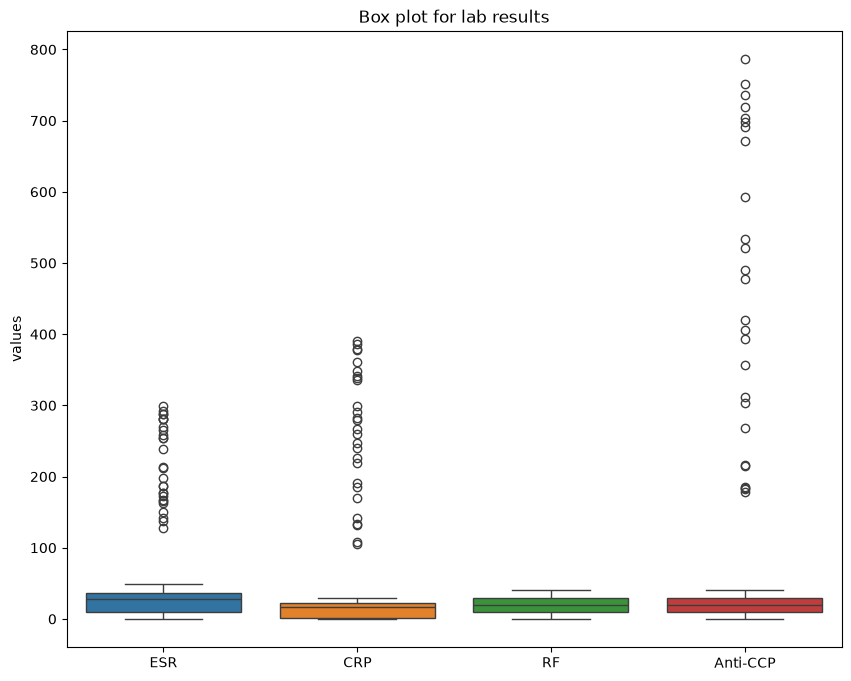

In [20]:
# box plot for outliers
numeric_labs = ["ESR", "CRP", "RF", "Anti-CCP"]
plt.figure(figsize=(10, 8))
sns.boxplot(data=df[numeric_labs])
plt.title("Box plot for lab results", fontsize=12)
plt.xticks(rotation=0)
plt.ylabel("values")
plt.show()

### I have changed all the dates int the Test_Date column into standard European time format and turned missing time into NAT.

In [21]:
# convert data types in Test_Date
# handling calendar dates and time durations
from datetime import datetime, timedelta

# importing pythons warning control library
import warnings


# takes a single value from Test_Date and converts into standardised pandas date time object
def Parse_Test_Date(val):
    if pd.isna(val):
        return pd.NaT

    # As Excel stores dates as number of days changing to correct calendar date
    if isinstance(val, (int, float)):
        return datetime(1899, 12, 30) + timedelta(days=val)
    try:
        return pd.to_datetime(val, dayfirst=True)
    except (ValueError, TypeError):
        return pd.NaT


# catches and suppresses user warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    df["Test_Date"] = df["Test_Date"].apply(Parse_Test_Date)
print(df["Test_Date"].head(20))

0    2019-02-25
1    2019-04-25
2    2020-05-29
3    2025-10-02
4    2020-06-15
5    2023-09-11
6    2021-06-12
7    2019-04-13
8    2022-02-09
9    2019-03-14
10   2022-05-02
11   2022-11-29
12   2022-08-26
13   2020-12-23
14   2024-05-14
15   2023-06-03
16   2020-10-13
17   2022-01-16
18   2019-05-10
19   2025-06-18
Name: Test_Date, dtype: datetime64[us]


### There are 428 null values in this column

In [22]:
# null values in Test_Date column
print(df["Test_Date"].isna().sum())

498


### Some dates could not be changed into dayfirst format and some are genuinely not dates, so they are kept as NaT


In [23]:
df_raw = pd.read_excel("Rheumatic and Autoimmune Disease Dataset_modified.xlsx")
still_failing = df_raw.loc[
    df["Test_Date"].isna() & df_raw["Test_Date"].notna(), "Test_Date"
]
print(still_failing.unique()[:20])

['00/00/0000' 'not a date' '31-02-2021' '2022-13-45' '2019-10-19'
 '17/08/2024' '01-25-2022' '2020-07-31 22:36:06' '2025-03-26' '12/03/2023'
 '09-21-2020' '2019-08-30' '2025-08-31' '29-Aug-2020' '08-Mar-2025'
 '22/03/2025' '12-16-2024' '2025-05-07' '16-Jul-2020' '2021-04-15']


### As test dates are important for prognosis I did not drop the missing values but converted into binary numbers so that no errors are thrown.

In [24]:
df["Test_Date_Missing"] = df["Test_Date"].isna().astype(int)
print(df[["Test_Date_Missing", "Test_Date"]].head(10))

   Test_Date_Missing  Test_Date
0                  0 2019-02-25
1                  0 2019-04-25
2                  0 2020-05-29
3                  0 2025-10-02
4                  0 2020-06-15
5                  0 2023-09-11
6                  0 2021-06-12
7                  0 2019-04-13
8                  0 2022-02-09
9                  0 2019-03-14


#### The column names  Age, Gender, ESR, CRP, RF, ANA, C3, C4, Disease  are single tokens ,so no separators needed.
#### Anti-CCP/HLA-B27/Anti-Ro/Anti-La/Anti-dsDNA/Anti-Sm are standard clinical nomenclature.
#### Test_Date is the only column name with a separator which is acceptable.
#### so the mixed styles are not inconsistencies.
#### I did not change the column name format


In [25]:
# Checking for inconsistencies in column names
df.columns

Index(['Age', 'Gender', 'Test_Date', 'ESR', 'CRP', 'RF', 'Anti-CCP', 'HLA-B27', 'ANA', 'Anti-Ro', 'Anti-La', 'Anti-dsDNA', 'Anti-Sm', 'C3',
       'C4', 'Disease', 'Test_Date_Missing'],
      dtype='str')

### Changed the variations f, female to into Female and m, male into Male for Gender.

In [26]:
# removing variations in categorical values
df["Gender"] = df["Gender"].astype(str).str.strip().str.lower()
gender_clean = {
    "f": "Female",
    "female": "Female",
    "m": "Male",
    "male": "Male",
}
# mapping the variations
df["Gender"] = df["Gender"].replace(gender_clean)
df["Gender"].head(10)

0      Male
1    Female
2    Female
3      Male
4    Female
5    Female
6      Male
7    Female
8    Female
9    Female
Name: Gender, dtype: str

#### I have changed the inconsistencies in format that is p, pos, positive into Positive and n, negative, neg into Negative in the columns  Anti-Ro, Anti-Sm, Anti-dsDNA. I prefer keeping the NAN values as I dont want to lose the data. I will handle it during the analysis if needed.

In [27]:
# removing the variations in the lab columns
lab_columns = ["Anti-Ro", "Anti-Sm", "Anti-dsDNA", "Anti-La"]
lab_clean = {
    "negative": "Negative",
    "neg": "Negative",
    "n": "Negative",
    "0": "Negative",
    "positive": "Positive",
    "pos.": "Positive",
    "pos": "Positive",
    "p": "Positive",
    "1": "Positive",
}
for col in lab_columns:
    df[col] = df[col].astype(str).str.strip().str.lower().replace(lab_clean)
    df[col] = df[col].where(df[col] != "unknown", "Unknown")
df[col].head(20)

0     Negative
1      Unknown
2     Positive
3     Positive
4     Negative
5     Negative
6      Unknown
7     Negative
8      Unknown
9      Unknown
10    Positive
11    Negative
12    Negative
13     Unknown
14     Unknown
15    Negative
16    Positive
17    Negative
18    Negative
19    Negative
Name: Anti-La, dtype: str

## PART 3: Feature Engineering.

### I have created a new feature which is the ratio of CRP(C-reactive protein) and ESR(Erythrocyte sedimentation rate ) as both are inflammatory markers and the ratio will be useful for checking whether the inflammation is acute or chronic

In [28]:
# 1) RATIO/RATE
df["CRP_ESR_ratio"] = df["CRP"] / df["ESR"].replace(0, pd.NA)
df[["CRP", "ESR", "CRP_ESR_ratio"]].head(10)

,CRP,ESR,CRP_ESR_ratio
0,18.6,39.0,0.476923
1,21.7,26.0,0.834615
2,15.6,41.0,0.380488
3,23.4,43.0,0.544186
4,20.7,30.0,0.69
5,12.5,36.0,0.347222
6,27.5,42.0,0.654762
7,19.3,39.0,0.494872
8,18.1,29.0,0.624138
9,20.7,37.0,0.559459


#### I have added the seropositive boolean flag for the lab values RF and Anti-CCP where the values above the threshold of the two labs will be presented as True or False. This will help in the diagnosis decision as they both are immunological markers.

In [29]:
# boolean flag
df["Seropositive"] = (df["RF"] > 20) | (df["Anti-CCP"] > 20)
print(df["Seropositive"].value_counts())
df[["RF", "Anti-CCP", "Seropositive"]].head()

Seropositive
True     7320
False    4765
Name: count, dtype: int64


,RF,Anti-CCP,Seropositive
0,34.2,29.9,True
1,35.5,28.9,True
2,21.3,21.3,True
3,26.0,39.0,True
4,38.1,30.8,True


#### I have categorised  the CRP levels which indicate inflammmation levels into 4 categories which tell the risk of having rheumatoid arthritis. In real world lab values have ranges. As I used pd.cut which needs non over lapping boundaries, I treated '3', '10', '100' as the cut off.I have binned them for easier clinical interpretation and to avoid noise of range of values in real world lab.

In [30]:
# categorical binning
CRP_bins = [-np.inf, 3, 10, 100, np.inf]
CRP_labels = ["Normal", "Mild Risk", "Moderate Risk", "High Risk"]
df["CRP_levels"] = pd.cut(df["CRP"], bins=CRP_bins, labels=CRP_labels)
df[["CRP", "CRP_levels"]].head(10)

,CRP,CRP_levels
0,18.6,Moderate Risk
1,21.7,Moderate Risk
2,15.6,Moderate Risk
3,23.4,Moderate Risk
4,20.7,Moderate Risk
5,12.5,Moderate Risk
6,27.5,Moderate Risk
7,19.3,Moderate Risk
8,18.1,Moderate Risk
9,20.7,Moderate Risk


### PART 4: Initial exploratory data analysis

#### Used .describe() to find the descriptive statistics 

In [31]:
# descriptive statistics
desc_stats = df[numeric_labs].describe()
print(desc_stats)

                ESR           CRP            RF      Anti-CCP
count  12085.000000  12085.000000  12085.000000  12085.000000
mean      24.663492     13.881837     19.660116     20.615565
std       17.267869     16.092279     11.135891     24.969078
min        0.000000      0.100000      0.000000      0.000000
25%       10.000000      1.700000     10.000000     10.000000
50%       28.000000     16.200000     19.700000     19.800000
75%       36.000000     21.700000     29.500000     29.700000
max      298.600000    389.900000     40.000000    786.700000


##### Univariate Analysis

### I used histogram for the univariate analysis of variable ESR, CRP. RF, Anti-CCP.
#### The Histogram of ESR shows that the frequency of test values are clustered between 0 to 50, peak being between 30 and 40. It is skewed to the right meaning more normal values with a few spikes.The bars are tightly packed with no gaps that most patients have similar lab values.The graph is Bimodal.
#### The CRP graph is right skewed with the bars tightly packed with the peak seen between 0 to 10 meaning most patients have low lab values.
#### The RF graph shows spikes at 10, 20, 30. The shape is uniform rectangular which is unusual for lab values indicating that the data is synthetic or distorted.
#### The Anti-CCP graph is right skewed with the peak between 0 to 10 indicating normal values in most of the patients.


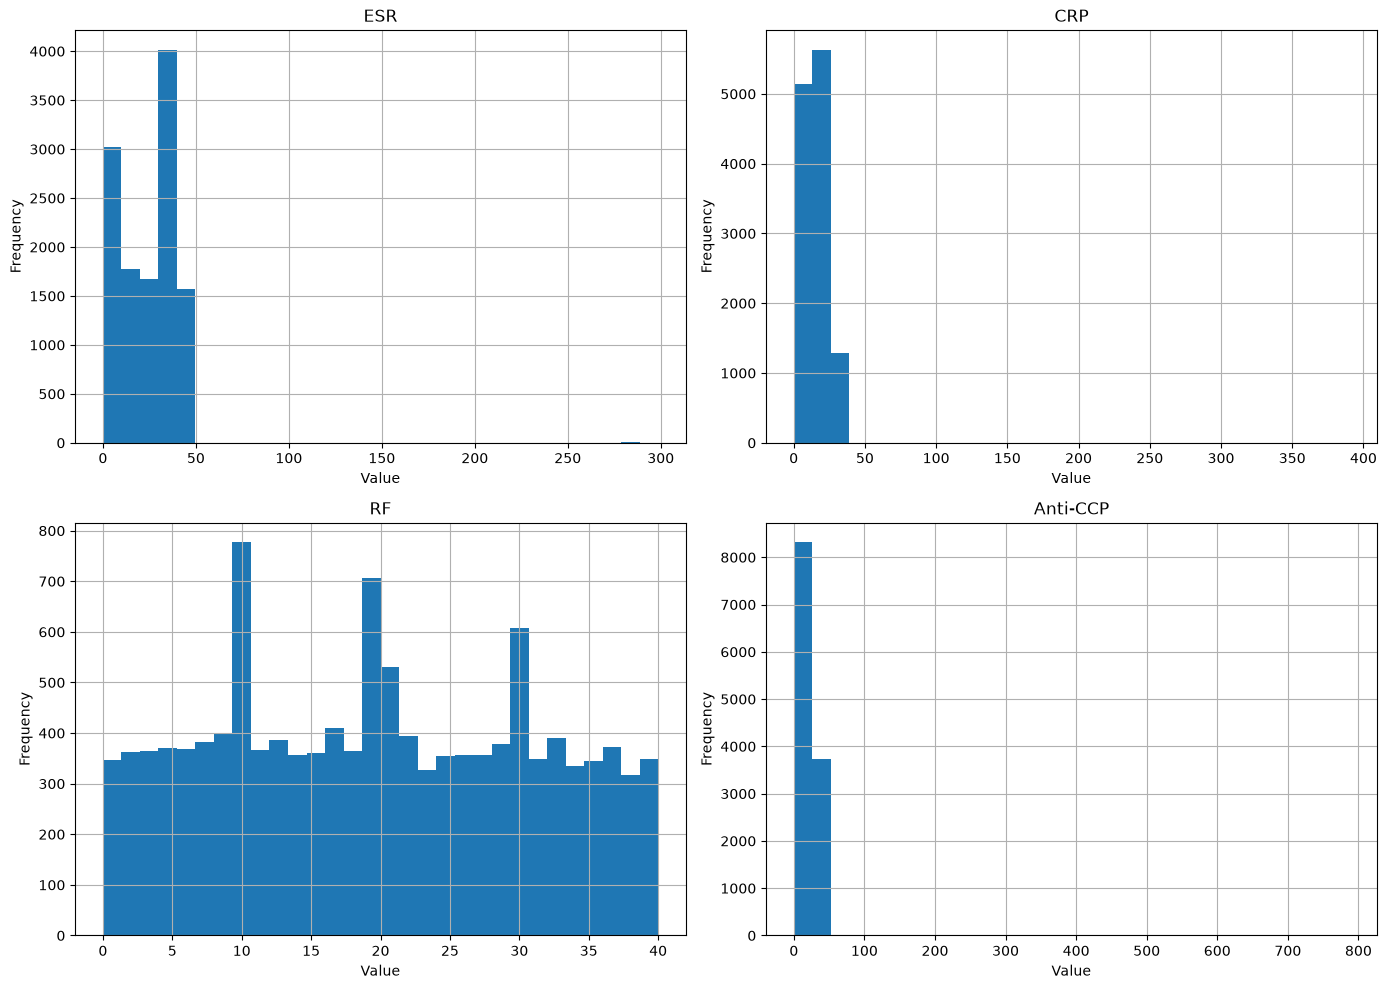

In [32]:
# Histogram for numeric_labs
# bins 30 divides each data range into 30 bars
axes = df[numeric_labs].hist(figsize=(14, 10), bins=30)

for ax in axes.ravel():  # .ravel flattens the grid into 1D list
    ax.set_xlabel("Value")
    ax.set_ylabel("Frequency")
plt.tight_layout()
plt.show()

#### ESR has central spread ~15-40.outliers are ~125-300 as isolated cluster.
#### CRP has central spread ~0-20 and tightly compressed indicating more patients with normal values. outliers are ~105-390 and has many patients in the outliers group.
#### RF central spread is ~10-30 and has no outliers.
#### Anti-CCP central spread is ~10-30 and has high frequency of outliers ~530-700.

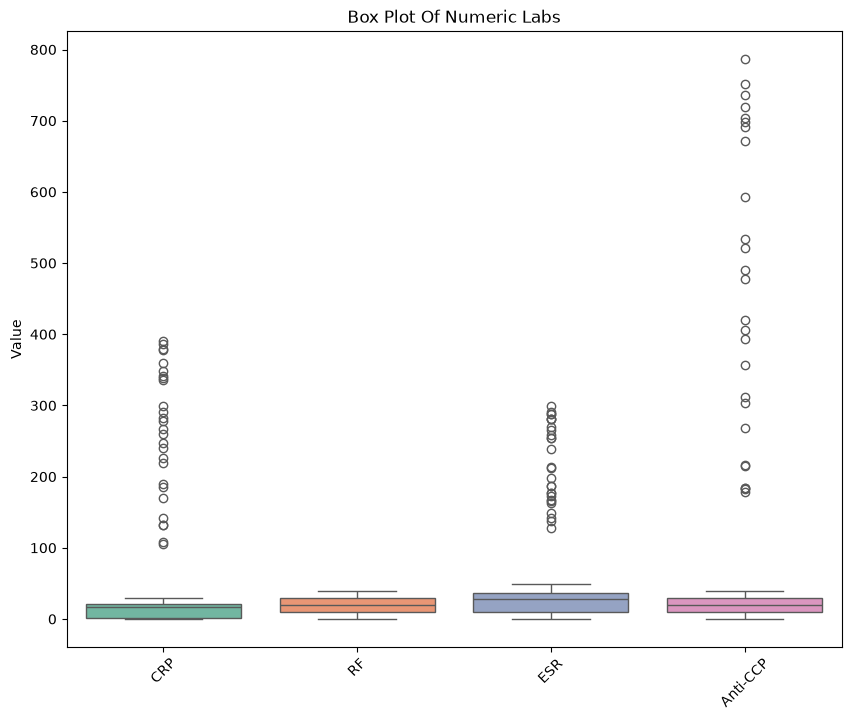

In [33]:
# box plot for the numeric labs
numeric_labs = ["CRP", "RF", "ESR", "Anti-CCP"]
plt.figure(figsize=(10, 8))
sns.boxplot(data=df[numeric_labs], palette="Set2")
plt.xticks(rotation=45)
plt.ylabel("Value")
plt.title("Box Plot Of Numeric Labs")
plt.show()

#### Bivariate Analysis

### Bivariate analysis
#### and ESR are the strongest pair(0.45). As they both are inflammatory markers so positive correlation is expected
#### The next strongest pair is of C3,C4(0.38).Expected as they belong to the same compliment cascade.
#### RF and Anti-CCP have weak correlation( ~0.15–0.21)
#### RF and C4 have no linear relationship

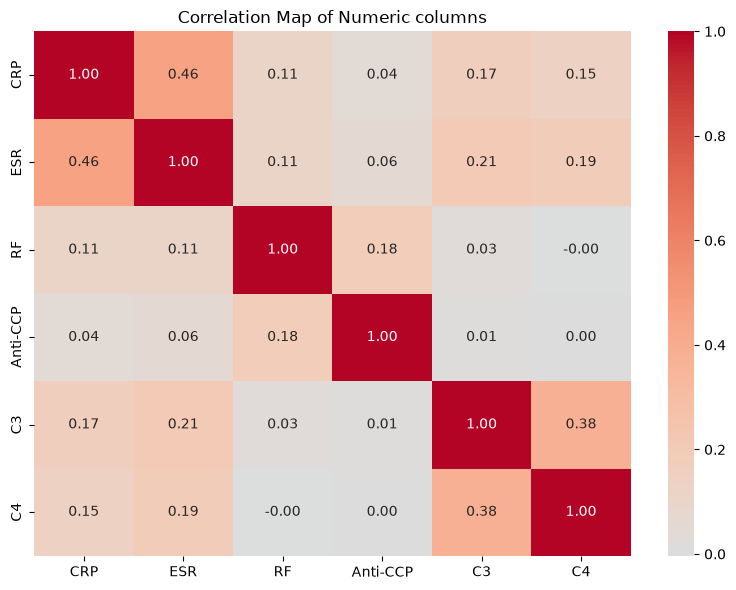

In [34]:
# bivariate analysis using correlation matrix
numeric_cols = ["CRP", "ESR", "RF", "Anti-CCP", "C3", "C4"]
corr = df[numeric_cols].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Map of Numeric columns")
plt.tight_layout()
plt.show()

#### I have used a heat map to show the relationship between biomarkers and disease which is the purpose of the dataset.
#### C3 and C4 are important for Systemic Lupus Erythematous.
#### RF and Anti-CCP peak in Rheumatoid Arthritis.
#### ESR and CRP increase in Psoriatic Arthritis and Ankylosing Spondylitis.
#### Normal is lowest in CRP and ESR but not on C3 and C4


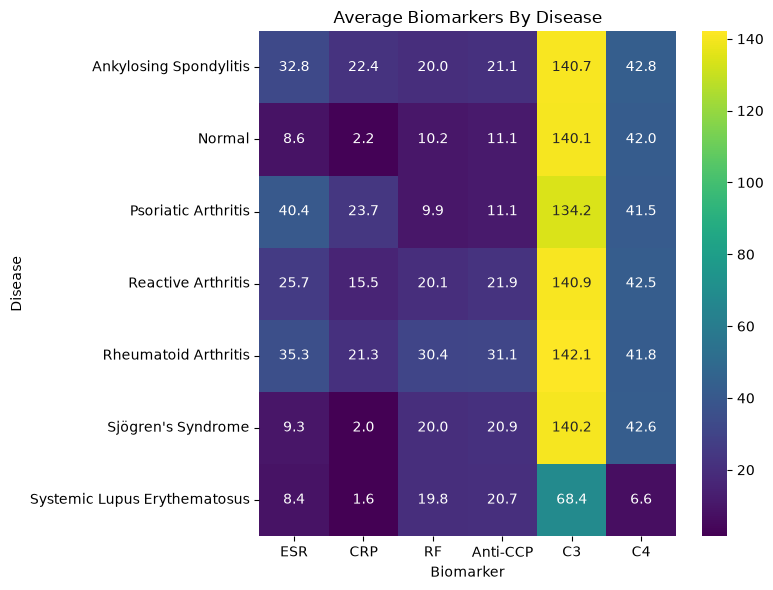

In [35]:
# Disease-by-biomarker heat map
# grouping unique categories in Disease column
disease_profile = df.groupby("Disease")[
    ["ESR", "CRP", "RF", "Anti-CCP", "C3", "C4"]
].mean()
plt.figure(figsize=(8, 6))
# annot=True writes the actual numeric average values in grid.fmt=.1f rounds up decimals
sns.heatmap(disease_profile, annot=True, fmt=".1f", cmap="viridis")
plt.title("Average Biomarkers By Disease")
plt.xlabel("Biomarker")
plt.ylabel("Disease")
plt.tight_layout()
plt.show()

### Exported as csv file

In [36]:
# export as csv file — df already has the cleaned, deduplicated and feature-engineered data
df.to_csv("Rheumatic and Autoimmune Disease Dataset_modified.csv", index=False)

In [37]:
exported_csv_rows = pd.read_csv(
    "Rheumatic and Autoimmune Disease Dataset_modified.csv"
).shape[0]

print(f"Rows after removing duplicates: {rows_after_dedup}")
print(f"Rows in exported csv:           {exported_csv_rows}")
print(f"Match: {rows_after_dedup == exported_csv_rows}")

Rows after removing duplicates: 12085
Rows in exported csv:           12085
Match: True


### checked if converted into csv file

In [38]:
# checking if converted into csv file
pd.read_csv("Rheumatic and Autoimmune Disease Dataset_modified.csv").head()

,Age,Gender,Test_Date,ESR,CRP,RF,Anti-CCP,HLA-B27,ANA,Anti-Ro,Anti-La,Anti-dsDNA,Anti-Sm,C3,C4,Disease,Test_Date_Missing,CRP_ESR_ratio,Seropositive,CRP_levels
0,70,Male,2019-02-25 00:00:00,39.0,18.6,34.2,29.9,Positive,Negative,Positive,Negative,Positive,Positive,143.0,27.0,Rheumatoid Arthritis,0,0.476923,True,Moderate Risk
1,39,Female,2019-04-25 00:00:00,26.0,21.7,35.5,28.9,Negative,Unknown,Positive,Unknown,Positive,Unknown,100.0,66.0,Rheumatoid Arthritis,0,0.834615,True,Moderate Risk
2,36,Female,2020-05-29 00:00:00,41.0,15.6,21.3,21.3,Negative,Negative,Unknown,Positive,Negative,Unknown,158.0,12.0,Rheumatoid Arthritis,0,0.380488,True,Moderate Risk
3,35,Male,2025-10-02 00:00:00,43.0,23.4,26.0,39.0,Unknown,Unknown,Positive,Positive,Unknown,Unknown,119.0,41.0,Rheumatoid Arthritis,0,0.544186,True,Moderate Risk
4,37,Female,2020-06-15 00:00:00,30.0,20.7,38.1,30.8,Positive,Negative,Positive,Negative,Positive,Negative,144.0,49.0,Rheumatoid Arthritis,0,0.690000,True,Moderate Risk


### I have checked the Age-Disease relationship using bar chart.
### The average affected age is between 40 and 50 for each disease.

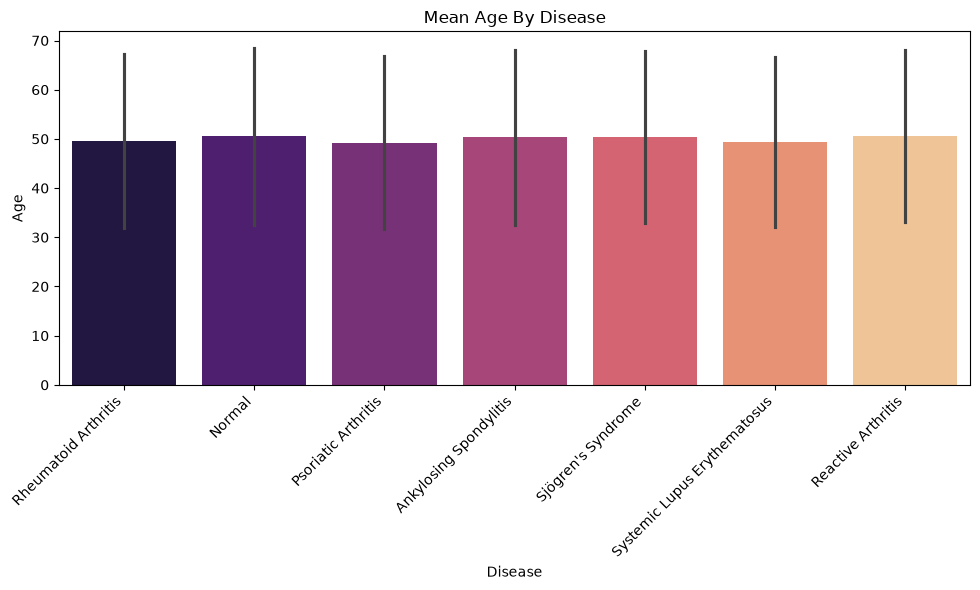

In [39]:
# Age Gender bar plot to check for their relation with the disease.
plt.figure(figsize=(10, 6))
sns.barplot(
    data=df,
    x="Disease",
    y="Age",
    errorbar="sd",
    hue="Disease",
    palette="magma",
    legend=False,
)
plt.xticks(rotation=45, ha="right")
plt.title("Mean Age By Disease")
plt.tight_layout()
plt.show()

### I used a count plot to check the relation between Gender and Disease.
### Males are slightly more affected in the diseases- Rheumatoid Arthritis,Psoriatic Arthritis, Sjogrens syndrome and Systemic Lupus Erythematosis.
### Count of females is more in normal.
### Both the genders are almost equal in Ankylosing Spondylitis and Reactive Arthritis.

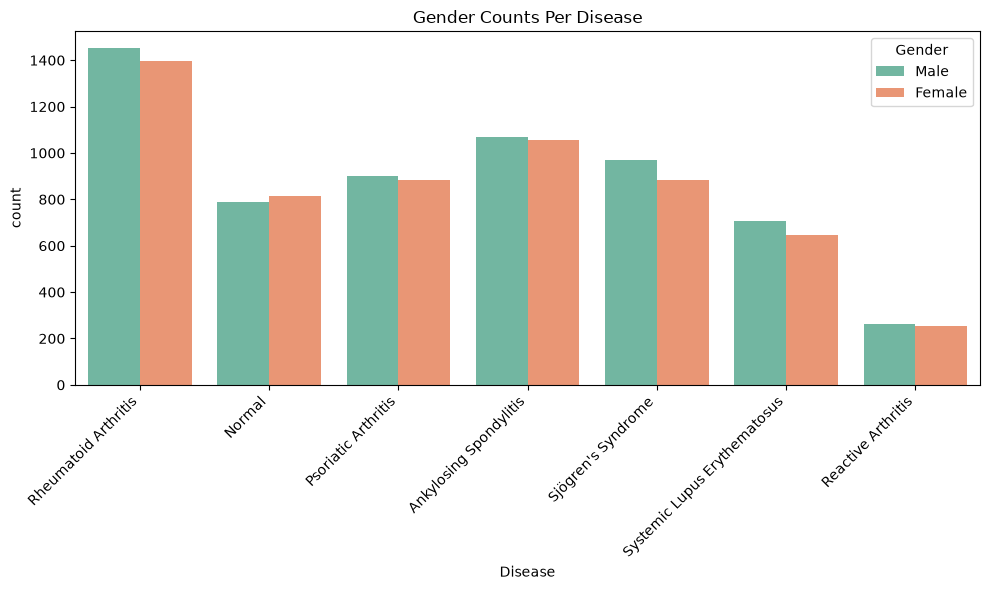

In [40]:
# count plot for Gender-Disease relation
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="Disease", hue="Gender", palette="Set2")
plt.xticks(rotation=45, ha="right")
plt.title("Gender Counts Per Disease")
plt.tight_layout()
plt.show()

### Observation
#### This dataset is a differential diagnostic dataset for 6 autoimmune disease:
#### 'Rheumatoid Arthritis', 'Ankylosing Spondylitis','Sjogrens's Syndrome', 'Psoriatic Arthritis', 'Systemic Lupus Arthritis' and 'Reactive Arthritis'.We also have normal people values for comparision.
#### Biomarkers are used for this differential diagnosis.
#### I have observed that each disease has a base line of biomarkers needed for its diagnosis and by knowing which biomarkers are positive disease diagnosis becomes easy.
#### The average age affected in each disease is between 40 and 50.
#### The Males have an edge over females in most of the diseases.
#### CRP and ESR are general inflammatory markers for all the 6 diseases.
#### missing values or null values means test is not done for that disease but does not indicate a messy dataset.
#### From the Disease-Biomarker heat map infer that for-
##### 1)Systemic Lupus Erythematous :C3 and C4 are main biomarkers
##### 2) Rheumatoid Arthritis : RF and Anti-CCP are important.
##### 3) Psoriatic Arthritis and Ankylosing Spondylitis : ESR and CRP increase
##### 4)  Normal is lowest in CRP and ESR but not on C3 and C4
#### This shows that as mentioned missing values in labs is not messy data as not all biomarkers are required to diagnose every disease.
#### I have decided to keep the outliers as they indicate patients with severity and removing them can cause a clinical bias.

### conclusion:
#### The above datset is helpful in learning correct Biomarker-Disease logic rather than clinical diagnosis